# CityLearn 데이터: 기본 ERD & EDA

연구 계획의 **기본 / EV / DR 시나리오**를 분리해 살펴봅니다.
ERD는 JSON 스키마의 **논리적 참조 관계**이며 CSV에 DB 기본키·외래키가 선언되어 있다는 뜻은 아닙니다.

- 전체 파일 요약, 스키마 관계, 건물·EV 설비 정의를 DataFrame으로 확인합니다.
- 모든 CSV의 컬럼·자료형·결측치·고유값·예시 값을 `columns_df`에 모읍니다.
- 아래 `DATASET`, `FILE`을 바꾸면 해당 파일의 컬럼 목록·원본·통계가 표시됩니다.
- 실행: `uv sync` 후 이 프로젝트의 `.venv` Python 커널에서 **Run All**.

원본 출처·커밋·주의사항: [data/README.md](data/README.md). 데이터는 수정하거나 합치지 않습니다.


In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
from IPython.display import display, Markdown, SVG

ROOT = Path.cwd()
if not (ROOT / 'data' / 'manifest.json').is_file():
    raise FileNotFoundError('프로젝트 루트에서 노트북을 실행하세요: data/manifest.json 필요')
DATA = ROOT / 'data'
manifest = json.loads((DATA / 'manifest.json').read_text())
schemas = {
    path.parent.name: json.loads(path.read_text())
    for path in sorted(DATA.glob('*/schema.json'))
}
tables = {
    (dataset, path.name): pd.read_csv(path)
    for dataset in schemas
    for path in sorted((DATA / dataset).glob('*.csv'))
}
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 90)
print(f"CityLearn 원본 커밋: {manifest['commit']}")
print(f'{len(schemas)}개 시나리오 / {len(tables)}개 CSV 로드')


CityLearn 원본 커밋: fd86484b8b438f03eb40c3ec06dc90caa349842d
3개 시나리오 / 71개 CSV 로드


## 1. 시나리오 및 파일 요약


In [2]:
datasets_df = pd.DataFrame([
    {
        'dataset': name,
        'buildings': len(schema['buildings']),
        'seconds_per_time_step': schema['seconds_per_time_step'],
        'start_step': schema['simulation_start_time_step'],
        'end_step': schema['simulation_end_time_step'],
        'start_date': schema.get('start_date'),
        'ev_definitions': len(schema.get('electric_vehicles_def', {})),
        'dr_enabled': schema.get('demand_response', {}).get('enabled', False),
    }
    for name, schema in schemas.items()
])
files_df = pd.DataFrame([
    {
        'dataset': dataset, 'file': filename,
        'rows': len(df), 'columns': len(df.columns),
        'missing_cells': int(df.isna().sum().sum()),
        'duplicate_rows': int(df.duplicated().sum()),
        'bytes': (DATA / dataset / filename).stat().st_size,
    }
    for (dataset, filename), df in tables.items()
])
display(datasets_df)
with pd.option_context('display.max_rows', None):
    display(files_df)


,dataset,buildings,seconds_per_time_step,start_step,end_step,start_date,ev_definitions,dr_enabled
0,citylearn_challenge_2022_phase_all,17,3600,0,8759,NaN,0,False
1,citylearn_challenge_2022_phase_all_demand_response,17,3600,0,8759,NaN,0,True
2,citylearn_challenge_2022_phase_all_plus_evs,17,3600,0,8759,2024-08-01,8,False


,dataset,file,rows,columns,missing_cells,duplicate_rows,bytes
0,citylearn_challenge_2022_phase_all,Building_1.csv,8760,12,26280,66,349473
1,citylearn_challenge_2022_phase_all,Building_10.csv,8760,12,26280,164,350339
2,citylearn_challenge_2022_phase_all,Building_11.csv,8760,12,26280,166,348376
3,citylearn_challenge_2022_phase_all,Building_12.csv,8760,12,26280,3238,370583
4,citylearn_challenge_2022_phase_all,Building_13.csv,8760,12,26280,0,348311
5,citylearn_challenge_2022_phase_all,Building_14.csv,8760,12,26280,26,353946
6,citylearn_challenge_2022_phase_all,Building_15.csv,8760,12,26280,3198,350365
7,citylearn_challenge_2022_phase_all,Building_16.csv,8760,12,26280,124,347298
8,citylearn_challenge_2022_phase_all,Building_17.csv,8760,12,26280,123,347470
9,citylearn_challenge_2022_phase_all,Building_2.csv,8760,12,26280,0,349891


## 2. 기본 ERD와 스키마 참조

`dataset + building_id`로 시나리오별 건물을 구분합니다. 각 건물은 건물 시계열과 공용 기상·가격·탄소 파일을 참조합니다.
충전기 CSV의 `electric_vehicle_id`는 스키마의 EV 정의를 가리킵니다. DR 요청은 시나리오 수준의 별도 이벤트 테이블입니다.
시간 인덱스는 CSV의 선언된 공통 PK가 아니며, EV·DR 간 자동 조인은 하지 않습니다.


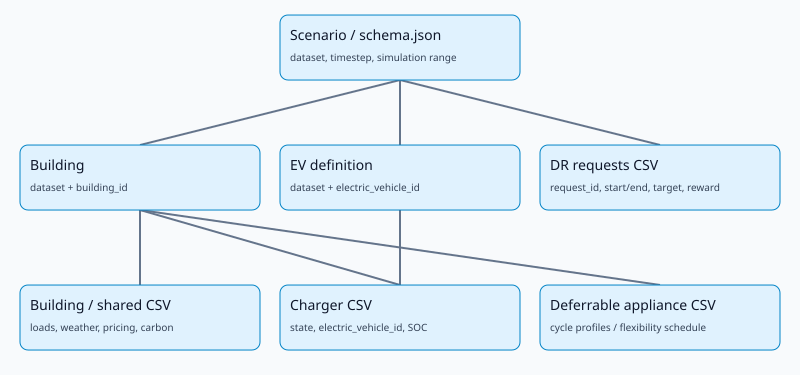

In [3]:
# 외부 렌더러 없이 노트북에 ERD를 표시합니다.
nodes = [
    (280, 15, 'Scenario / schema.json', 'dataset, timestep, simulation range'),
    (20, 145, 'Building', 'dataset + building_id'),
    (280, 145, 'EV definition', 'dataset + electric_vehicle_id'),
    (540, 145, 'DR requests CSV', 'request_id, start/end, target, reward'),
    (20, 285, 'Building / shared CSV', 'loads, weather, pricing, carbon'),
    (280, 285, 'Charger CSV', 'state, electric_vehicle_id, SOC'),
    (540, 285, 'Deferrable appliance CSV', 'cycle profiles / flexibility schedule'),
]
edges = [(400, 80, 140, 145), (400, 80, 400, 145), (400, 80, 660, 145),
         (140, 210, 140, 285), (140, 210, 400, 285),
         (400, 285, 400, 210), (140, 210, 660, 285)]
svg = '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 800 375" role="img" aria-label="CityLearn logical data relationships">'
svg += '<rect width="800" height="375" fill="#f8fafc"/>'
for x1, y1, x2, y2 in edges:
    svg += f'<path d="M{x1},{y1} L{x2},{y2}" stroke="#64748b" stroke-width="2" fill="none"/>'
for x, y, title, detail in nodes:
    svg += f'<rect x="{x}" y="{y}" width="240" height="65" rx="8" fill="#e0f2fe" stroke="#0284c7"/>'
    svg += f'<text x="{x + 10}" y="{y + 25}" font-size="14" font-family="sans-serif" fill="#0f172a">{title}</text>'
    svg += f'<text x="{x + 10}" y="{y + 46}" font-size="10" font-family="sans-serif" fill="#334155">{detail}</text>'
display(SVG(svg + '</svg>'))


In [4]:
# 스키마의 CSV 참조 경로를 그대로 보존합니다.
references = []
def collect_references(dataset, value, path='schema'):
    if isinstance(value, dict):
        for key, child in value.items():
            collect_references(dataset, child, f'{path}.{key}')
    elif isinstance(value, list):
        for index, child in enumerate(value):
            collect_references(dataset, child, f'{path}[{index}]')
    elif isinstance(value, str) and value.endswith('.csv'):
        references.append({'dataset': dataset, 'schema_path': path, 'csv_file': value,
                           'exists': (DATA / dataset / value).is_file()})

for dataset, schema in schemas.items():
    collect_references(dataset, schema)
relations_df = pd.DataFrame(references)
assert relations_df['exists'].all(), '스키마에 참조된 파일이 누락되었습니다.'
with pd.option_context('display.max_rows', None):
    display(relations_df)


,dataset,schema_path,csv_file,exists
0,citylearn_challenge_2022_phase_all,schema.buildings.Building_1.energy_simulation,Building_1.csv,True
1,citylearn_challenge_2022_phase_all,schema.buildings.Building_1.weather,weather.csv,True
2,citylearn_challenge_2022_phase_all,schema.buildings.Building_1.carbon_intensity,carbon_intensity.csv,True
3,citylearn_challenge_2022_phase_all,schema.buildings.Building_1.pricing,pricing.csv,True
4,citylearn_challenge_2022_phase_all,schema.buildings.Building_2.energy_simulation,Building_2.csv,True
5,citylearn_challenge_2022_phase_all,schema.buildings.Building_2.weather,weather.csv,True
6,citylearn_challenge_2022_phase_all,schema.buildings.Building_2.carbon_intensity,carbon_intensity.csv,True
7,citylearn_challenge_2022_phase_all,schema.buildings.Building_2.pricing,pricing.csv,True
8,citylearn_challenge_2022_phase_all,schema.buildings.Building_3.energy_simulation,Building_3.csv,True
9,citylearn_challenge_2022_phase_all,schema.buildings.Building_3.weather,weather.csv,True


### 건물·저장장치·태양광 및 EV 정의 (DataFrame)


In [5]:
buildings_df = pd.json_normalize([
    dict(dataset=dataset, building_id=building_id, **config)
    for dataset, schema in schemas.items()
    for building_id, config in schema['buildings'].items()
])
evs_df = pd.json_normalize([
    dict(dataset=dataset, electric_vehicle_id=ev_id, **config)
    for dataset, schema in schemas.items()
    for ev_id, config in schema.get('electric_vehicles_def', {}).items()
])
display(buildings_df)
display(evs_df)


,dataset,building_id,include,energy_simulation,weather,carbon_intensity,pricing,inactive_observations,inactive_actions,electrical_storage.type,electrical_storage.autosize,electrical_storage.attributes.capacity,electrical_storage.attributes.efficiency,electrical_storage.attributes.capacity_loss_coefficient,electrical_storage.attributes.loss_coefficient,electrical_storage.attributes.nominal_power,pv.type,pv.autosize,pv.attributes.nominal_power,chargers.charger_1_1.type,chargers.charger_1_1.charger_simulation,chargers.charger_1_1.autosize,chargers.charger_1_1.attributes.nominal_power,chargers.charger_1_1.attributes.efficiency,chargers.charger_1_1.attributes.charger_type,chargers.charger_1_1.attributes.max_charging_power,chargers.charger_1_1.attributes.min_charging_power,chargers.charger_1_1.attributes.max_discharging_power,chargers.charger_1_1.attributes.min_discharging_power,deferrable_appliances.deferrable_appliance_1.type,deferrable_appliances.deferrable_appliance_1.autosize,deferrable_appliances.deferrable_appliance_1.cycle_profiles_file,deferrable_appliances.deferrable_appliance_1.flexibility_schedule_file,chargers.charger_4_1.type,chargers.charger_4_1.charger_simulation,chargers.charger_4_1.autosize,chargers.charger_4_1.attributes.nominal_power,chargers.charger_4_1.attributes.efficiency,chargers.charger_4_1.attributes.charger_type,chargers.charger_4_1.attributes.max_charging_power,chargers.charger_4_1.attributes.min_charging_power,chargers.charger_4_1.attributes.max_discharging_power,chargers.charger_4_1.attributes.min_discharging_power,chargers.charger_5_1.type,chargers.charger_5_1.charger_simulation,chargers.charger_5_1.autosize,chargers.charger_5_1.attributes.nominal_power,chargers.charger_5_1.attributes.efficiency,chargers.charger_5_1.attributes.charger_type,chargers.charger_5_1.attributes.max_charging_power,chargers.charger_5_1.attributes.min_charging_power,chargers.charger_5_1.attributes.max_discharging_power,chargers.charger_5_1.attributes.min_discharging_power,chargers.charger_7_1.type,chargers.charger_7_1.charger_simulation,chargers.charger_7_1.autosize,chargers.charger_7_1.attributes.nominal_power,chargers.charger_7_1.attributes.efficiency,chargers.charger_7_1.attributes.charger_type,chargers.charger_7_1.attributes.max_charging_power,chargers.charger_7_1.attributes.min_charging_power,chargers.charger_7_1.attributes.max_discharging_power,chargers.charger_7_1.attributes.min_discharging_power,chargers.charger_10_1.type,chargers.charger_10_1.charger_simulation,chargers.charger_10_1.autosize,chargers.charger_10_1.attributes.nominal_power,chargers.charger_10_1.attributes.efficiency,chargers.charger_10_1.attributes.charger_type,chargers.charger_10_1.attributes.max_charging_power,chargers.charger_10_1.attributes.min_charging_power,chargers.charger_10_1.attributes.max_discharging_power,chargers.charger_10_1.attributes.min_discharging_power,chargers.charger_12_1.type,chargers.charger_12_1.charger_simulation,chargers.charger_12_1.autosize,chargers.charger_12_1.attributes.nominal_power,chargers.charger_12_1.attributes.efficiency,chargers.charger_12_1.attributes.charger_type,chargers.charger_12_1.attributes.max_charging_power,chargers.charger_12_1.attributes.min_charging_power,chargers.charger_12_1.attributes.max_discharging_power,chargers.charger_12_1.attributes.min_discharging_power,chargers.charger_15_1.type,chargers.charger_15_1.charger_simulation,chargers.charger_15_1.autosize,chargers.charger_15_1.attributes.nominal_power,chargers.charger_15_1.attributes.efficiency,chargers.charger_15_1.attributes.charger_type,chargers.charger_15_1.attributes.max_charging_power,chargers.charger_15_1.attributes.min_charging_power,chargers.charger_15_1.attributes.max_discharging_power,chargers.charger_15_1.attributes.min_discharging_power,chargers.charger_15_2.type,chargers.charger_15_2.charger_simulation,chargers.charger_15_2.autosize,chargers.charger_15_2.attributes.nominal_power,chargers.charger_15_2.attributes.efficiency,chargers.charg

,dataset,electric_vehicle_id,include,battery.type,battery.autosize,battery.attributes.capacity,battery.attributes.nominal_power,battery.attributes.initial_soc,battery.attributes.depth_of_discharge
0,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_1,True,citylearn.energy_model.Battery,False,40,50,0.25,0.85
1,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_2,True,citylearn.energy_model.Battery,False,50,50,NaN,0.90
2,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_3,True,citylearn.energy_model.Battery,False,75,50,NaN,0.80
3,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_4,True,citylearn.energy_model.Battery,False,45,50,NaN,0.90
4,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_5,True,citylearn.energy_model.Battery,False,90,50,NaN,0.85
5,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_6,True,citylearn.energy_model.Battery,False,100,50,NaN,0.90
6,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_7,True,citylearn.energy_model.Battery,False,60,50,0.25,0.80
7,citylearn_challenge_2022_phase_all_plus_evs,Electric_Vehicle_8,True,citylearn.energy_model.Battery,False,80,50,0.20,0.85


## 3. 전체 컬럼 카탈로그 (DataFrame)

`columns_df`에는 **모든 CSV의 모든 컬럼**이 있습니다. 자료형은 pandas 추론 결과이고, 단위는 컬럼명·CityLearn 데이터 계약으로 확인해야 합니다.
`null_pct`는 결측 비율(%), `n_unique`는 결측값을 제외한 고유값 수입니다.
아래 표는 같은 시나리오에서 컬럼 이름·자료형·소속 파일 목록을 묶은 전체 컬럼 안내입니다. 파일별 값은 다음 절에서 확인합니다.


In [6]:
column_records = []
for (dataset, filename), df in tables.items():
    for column in df.columns:
        series = df[column]
        samples = series.dropna().drop_duplicates().head(3).tolist()
        column_records.append({
            'dataset': dataset, 'file': filename, 'column': column,
            'dtype': str(series.dtype), 'non_null': int(series.notna().sum()),
            'null_count': int(series.isna().sum()),
            'null_pct': round(float(series.isna().mean() * 100), 2),
            'n_unique': int(series.nunique()),
            'examples': repr(samples),
        })
columns_df = pd.DataFrame(column_records)
column_catalog_df = (
    columns_df.groupby(['dataset', 'column', 'dtype'], sort=False)['file']
    .agg(file_count='size', files=lambda values: ', '.join(values))
    .reset_index()
)
with pd.option_context('display.max_rows', None):
    display(column_catalog_df)


,dataset,column,dtype,file_count,files
0,citylearn_challenge_2022_phase_all,month,int64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
1,citylearn_challenge_2022_phase_all,hour,int64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
2,citylearn_challenge_2022_phase_all,day_type,int64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
3,citylearn_challenge_2022_phase_all,daylight_savings_status,int64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
4,citylearn_challenge_2022_phase_all,indoor_dry_bulb_temperature,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
5,citylearn_challenge_2022_phase_all,average_unmet_cooling_setpoint_difference,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
6,citylearn_challenge_2022_phase_all,indoor_relative_humidity,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
7,citylearn_challenge_2022_phase_all,non_shiftable_load,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
8,citylearn_challenge_2022_phase_all,dhw_demand,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."
9,citylearn_challenge_2022_phase_all,cooling_demand,float64,17,"Building_1.csv, Building_10.csv, Building_11.csv, Building_12.csv, Building_13.csv, Bu..."


## 4. 선택한 파일: 컬럼·원본·통계

아래 두 변수를 바꾸고 이후 셀을 재실행하세요. `files_df`에서 시나리오와 파일명을 고를 수 있습니다.
숫자로 인코딩된 상태·달력·식별자의 평균은 물리적 의미가 없을 수 있습니다.


In [7]:
DATASET = 'citylearn_challenge_2022_phase_all_plus_evs'
FILE = 'Building_1.csv'

if (DATASET, FILE) not in tables:
    raise KeyError('files_df에 있는 dataset / file 조합을 선택하세요.')
df = tables[(DATASET, FILE)]
display(Markdown(f'### `{DATASET}` / `{FILE}` — {len(df):,}행 × {len(df.columns)}열'))
selected_columns_df = columns_df.loc[
    (columns_df['dataset'] == DATASET) & (columns_df['file'] == FILE)
].reset_index(drop=True)
with pd.option_context('display.max_rows', None):
    display(selected_columns_df)
display(df.head(10))


### `citylearn_challenge_2022_phase_all_plus_evs` / `Building_1.csv` — 8,760행 × 12열

,dataset,file,column,dtype,non_null,null_count,null_pct,n_unique,examples
0,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,month,int64,8760,0,0.0,12,"[8, 9, 10]"
1,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,hour,int64,8760,0,0.0,25,"[0, 1, 2]"
2,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,day_type,int64,8760,0,0.0,7,"[1, 2, 3]"
3,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,daylight_savings_status,int64,8760,0,0.0,1,[0]
4,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,indoor_dry_bulb_temperature,float64,0,8760,100.0,0,[]
5,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,average_unmet_cooling_setpoint_difference,float64,0,8760,100.0,0,[]
6,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,indoor_relative_humidity,float64,0,8760,100.0,0,[]
7,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,non_shiftable_load,float64,8760,0,0.0,8249,"[2.2758, 0.85116667, 0.8346]"
8,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,dhw_demand,float64,8760,0,0.0,1,[0.0]
9,citylearn_challenge_2022_phase_all_plus_evs,Building_1.csv,cooling_demand,float64,8760,0,0.0,1,[0.0]


,month,hour,day_type,daylight_savings_status,indoor_dry_bulb_temperature,average_unmet_cooling_setpoint_difference,indoor_relative_humidity,non_shiftable_load,dhw_demand,cooling_demand,heating_demand,solar_generation
0,8,0,1,0,NaN,NaN,NaN,2.275800,0.0,0.0,0.0,0.000000
1,8,1,1,0,NaN,NaN,NaN,0.851167,0.0,0.0,0.0,0.000000
2,8,2,1,0,NaN,NaN,NaN,0.834600,0.0,0.0,0.0,0.000000
3,8,3,1,0,NaN,NaN,NaN,0.838167,0.0,0.0,0.0,0.000000
4,8,4,1,0,NaN,NaN,NaN,1.478433,0.0,0.0,0.0,0.000000
5,8,5,1,0,NaN,NaN,NaN,1.256200,0.0,0.0,0.0,0.000000
6,8,6,1,0,NaN,NaN,NaN,1.869517,0.0,0.0,0.0,14.504167
7,8,7,1,0,NaN,NaN,NaN,0.808817,0.0,0.0,0.0,111.520836
8,8,8,1,0,NaN,NaN,NaN,0.615967,0.0,0.0,0.0,276.470830
9,8,9,1,0,NaN,NaN,NaN,0.627233,0.0,0.0,0.0,453.025000


In [8]:
numeric_df = df.select_dtypes(include='number')
if not numeric_df.empty:
    display(Markdown('### 수치형 통계'))
    display(numeric_df.describe().T.rename_axis('column').reset_index())
category_df = df.select_dtypes(exclude='number')
if not category_df.empty:
    display(Markdown('### 비수치형 통계'))
    display(category_df.describe().T.rename_axis('column').reset_index())


### 수치형 통계

,column,count,mean,std,min,25%,50%,75%,max
0,month,8760.0,6.526142,3.448080,1.000,4.000000,7.000000,10.000000,12.000000
1,hour,8760.0,12.497260,6.922779,0.000,6.000000,12.000000,18.000000,24.000000
2,day_type,8760.0,3.991781,2.003519,1.000,2.000000,4.000000,6.000000,7.000000
3,daylight_savings_status,8760.0,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000
4,indoor_dry_bulb_temperature,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,average_unmet_cooling_setpoint_difference,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,indoor_relative_humidity,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,non_shiftable_load,8760.0,1.208145,0.968270,0.057,0.570167,0.812079,1.530529,7.987483
8,dhw_demand,8760.0,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000
9,cooling_demand,8760.0,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000


## 5. EV·DR·유연부하 파일 미리보기 및 컬럼


In [9]:
for (dataset, filename), table in tables.items():
    # 반복되는 충전기 파일은 한 개만 펼칩니다. 나머지도 columns_df / tables에 있습니다.
    if filename == 'charger_1_1.csv' or filename.startswith(('demand_response_', 'deferrable_')):
        display(Markdown(f'### `{dataset}` / `{filename}`'))
        with pd.option_context('display.max_rows', None):
            display(columns_df.loc[
                (columns_df['dataset'] == dataset) & (columns_df['file'] == filename)
            ].reset_index(drop=True))
        display(table.head())


### `citylearn_challenge_2022_phase_all_demand_response` / `demand_response_requests.csv`

,dataset,file,column,dtype,non_null,null_count,null_pct,n_unique,examples
0,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,request_id,str,3,0,0.0,3,"['dr_day_002_evening_down', 'dr_day_004_midday_up', 'dr_day_008_evening_down']"
1,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,issuer,str,3,0,0.0,2,"['dso', 'tso']"
2,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,direction,str,3,0,0.0,2,"['down', 'up']"
3,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,start_time_step,int64,3,0,0.0,3,"[24, 84, 168]"
4,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,end_time_step,int64,3,0,0.0,3,"[26, 86, 171]"
5,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,target_power_kw,float64,3,0,0.0,3,"[20.0, 10.0, 25.0]"
6,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,activation_price_eur_per_kwh,float64,3,0,0.0,3,"[0.35, 0.25, 0.4]"
7,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,shortfall_penalty_eur_per_kwh,float64,3,0,0.0,3,"[1.2, 0.8, 1.5]"
8,citylearn_challenge_2022_phase_all_demand_response,demand_response_requests.csv,tolerance_power_kw,float64,3,0,0.0,2,"[1.0, 0.5]"


,request_id,issuer,direction,start_time_step,end_time_step,target_power_kw,activation_price_eur_per_kwh,shortfall_penalty_eur_per_kwh,tolerance_power_kw
0,dr_day_002_evening_down,dso,down,24,26,20.0,0.35,1.2,1.0
1,dr_day_004_midday_up,tso,up,84,86,10.0,0.25,0.8,0.5
2,dr_day_008_evening_down,dso,down,168,171,25.0,0.40,1.5,1.0


### `citylearn_challenge_2022_phase_all_plus_evs` / `charger_1_1.csv`

,dataset,file,column,dtype,non_null,null_count,null_pct,n_unique,examples
0,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_charger_state,int64,9527,0,0.00,3,"[1, 3, 2]"
1,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_id,str,6808,2719,28.54,1,['Electric_Vehicle_7']
2,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_departure_time,float64,6279,3248,34.09,21,"[12.0, 11.0, 10.0]"
3,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_required_soc_departure,float64,6279,3248,34.09,35,"[87.0, 88.0, 89.0]"
4,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_estimated_arrival_time,float64,529,8998,94.45,5,"[0.0, 1.0, 2.0]"
5,citylearn_challenge_2022_phase_all_plus_evs,charger_1_1.csv,electric_vehicle_estimated_soc_arrival,float64,527,9000,94.47,82,"[76.0, 84.0, 62.0]"


,electric_vehicle_charger_state,electric_vehicle_id,electric_vehicle_departure_time,electric_vehicle_required_soc_departure,electric_vehicle_estimated_arrival_time,electric_vehicle_estimated_soc_arrival
0,1,Electric_Vehicle_7,12.0,87.0,NaN,NaN
1,1,Electric_Vehicle_7,11.0,87.0,NaN,NaN
2,1,Electric_Vehicle_7,10.0,87.0,NaN,NaN
3,1,Electric_Vehicle_7,9.0,87.0,NaN,NaN
4,1,Electric_Vehicle_7,8.0,87.0,NaN,NaN


... (2 outputs left out)

,profile_id,duration_steps,total_energy_kwh,load_profile
0,deferrable_appliance_1_profile_001,1,3.157,[3.157]
1,deferrable_appliance_1_profile_002,2,10.345,"[3.647,6.698]"
2,deferrable_appliance_1_profile_003,3,18.783,"[3.073,3.0940000000000003,12.616]"
3,deferrable_appliance_1_profile_004,2,47.748,"[37.588,10.16]"
4,deferrable_appliance_1_profile_005,1,3.094,[3.0940000000000003]


### `citylearn_challenge_2022_phase_all_plus_evs` / `deferrable_appliance_1_flexibility_schedule.csv`

,dataset,file,column,dtype,non_null,null_count,null_pct,n_unique,examples
0,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,cycle_id,str,365,0,0.0,365,"['deferrable_appliance_1_cycle_0001', 'deferrable_appliance_1_cycle_0002', 'deferrable..."
1,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,profile_id,str,365,0,0.0,315,"['deferrable_appliance_1_profile_001', 'deferrable_appliance_1_profile_002', 'deferrab..."
2,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,earliest_start_time_step,int64,365,0,0.0,365,"[1, 29, 49]"
3,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,latest_start_time_step,int64,365,0,0.0,365,"[3, 31, 52]"
4,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,deadline_time_step,int64,365,0,0.0,365,"[3, 32, 54]"
5,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,priority,float64,365,0,0.0,1,[1.0]
6,citylearn_challenge_2022_phase_all_plus_evs,deferrable_appliance_1_flexibility_schedule.csv,must_run,bool,365,0,0.0,1,[True]


,cycle_id,profile_id,earliest_start_time_step,latest_start_time_step,deadline_time_step,priority,must_run
0,deferrable_appliance_1_cycle_0001,deferrable_appliance_1_profile_001,1,3,3,1.0,True
1,deferrable_appliance_1_cycle_0002,deferrable_appliance_1_profile_002,29,31,32,1.0,True
2,deferrable_appliance_1_cycle_0003,deferrable_appliance_1_profile_003,49,52,54,1.0,True
3,deferrable_appliance_1_cycle_0004,deferrable_appliance_1_profile_004,73,75,76,1.0,True
4,deferrable_appliance_1_cycle_0005,deferrable_appliance_1_profile_005,98,99,99,1.0,True


## 6. 무결성 및 통합 전 점검

해시 일치는 다운로드 원본과 같다는 뜻이며 데이터의 물리적 정확성을 증명하지는 않습니다.
반복 행은 정상적인 부하·가격·대기 상태일 수 있어 삭제하지 않습니다. EV의 빈 도착 정보도 상태 조건에 따른 정상 결측일 수 있습니다.


In [10]:
integrity_df = pd.DataFrame([
    {'file': item['path'],
     'sha256_matches': hashlib.sha256((DATA / item['path']).read_bytes()).hexdigest() == item['sha256']}
    for item in manifest['files']
])
assert integrity_df['sha256_matches'].all(), '다운로드 후 변경된 원본 파일이 있습니다.'
assert len(columns_df) == sum(len(table.columns) for table in tables.values())
assert len(files_df) == len(tables)
print(f"원본 해시 {len(integrity_df)}개 및 컬럼 카탈로그 {len(columns_df)}개 항목 검증 완료")

BASE = 'citylearn_challenge_2022_phase_all'
comparison = []
for dataset in schemas:
    if dataset == BASE:
        continue
    for (source, filename), base_table in tables.items():
        if source != BASE or (dataset, filename) not in tables:
            continue
        other = tables[(dataset, filename)]
        calendar_cols = [column for column in ['month', 'hour', 'day_type', 'daylight_savings_status']
                         if column in base_table and column in other]
        comparison.append({
            'dataset': dataset, 'file': filename,
            'same_shape': base_table.shape == other.shape,
            'same_values': base_table.equals(other),
            'calendar_matches': base_table[calendar_cols].equals(other[calendar_cols]) if calendar_cols else None,
        })
comparison_df = pd.DataFrame(comparison)
with pd.option_context('display.max_rows', None):
    display(comparison_df)


원본 해시 74개 및 컬럼 카탈로그 743개 항목 검증 완료


,dataset,file,same_shape,same_values,calendar_matches
0,citylearn_challenge_2022_phase_all_demand_response,Building_1.csv,True,True,True
1,citylearn_challenge_2022_phase_all_demand_response,Building_10.csv,True,True,True
2,citylearn_challenge_2022_phase_all_demand_response,Building_11.csv,True,True,True
3,citylearn_challenge_2022_phase_all_demand_response,Building_12.csv,True,True,True
4,citylearn_challenge_2022_phase_all_demand_response,Building_13.csv,True,True,True
5,citylearn_challenge_2022_phase_all_demand_response,Building_14.csv,True,True,True
6,citylearn_challenge_2022_phase_all_demand_response,Building_15.csv,True,True,True
7,citylearn_challenge_2022_phase_all_demand_response,Building_16.csv,True,True,True
8,citylearn_challenge_2022_phase_all_demand_response,Building_17.csv,True,True,True
9,citylearn_challenge_2022_phase_all_demand_response,Building_2.csv,True,True,True


### 연구 해석 주의사항

- EV·DR 예제의 공통 건물 이름만으로 동일한 물리적 건물·시간축이라고 판단하지 않습니다. 위 비교표로 차이를 확인합니다.
- 충전기 파일 길이가 건물의 8,760행과 다릅니다. 로더의 시간 처리 확인 전 행 번호로 병합하거나 잘라내지 않습니다.
- EV 파일의 **실측/합성 여부는 미확인**입니다. 공식 예제에 존재한다는 사실만으로 실측 세션이라 부르지 않습니다.
- 유연부하 파일과 스키마 정의는 존재하지만 SOC·출발 마감·충전 출력·설비 실행가능성은 이 기초 분석에서 검증하지 않습니다.
- 시계열에 별도 날짜를 만들거나 EV·DR 통합 데이터를 생성하지 않습니다.


## 7. 연구 계획의 실험 가능 여부 점검

아래 검사는 **입력 데이터와 설비 구성의 정적 검사**입니다. CityLearn 환경 실행, 실행가능 스케줄 생성, QAOA·고전 솔버 성능 측정을 대신하지 않습니다.
건물 수는 EV 충전기를 보유하고 `include=True`인 건물만 집계합니다. 배터리만 사용하는 다른 건물을 포함하는 실험은 별도 문제 구성입니다.


In [11]:
EV_DATASET = 'citylearn_challenge_2022_phase_all_plus_evs'
DR_DATASET = 'citylearn_challenge_2022_phase_all_demand_response'
ev_schema = schemas[EV_DATASET]
dr_schema = schemas[DR_DATASET]
ev_definitions = ev_schema['electric_vehicles_def']
charger_checks = []
for building_id, building in ev_schema['buildings'].items():
    if not building.get('include', True):
        continue
    for charger_id, config in building.get('chargers', {}).items():
        data = tables[(EV_DATASET, config['charger_simulation'])]
        ids = set(data['electric_vehicle_id'].dropna())
        soc = pd.to_numeric(data['electric_vehicle_required_soc_departure'], errors='coerce').dropna()
        battery_ok = bool(ids) and all(
            ev_definitions.get(ev_id, {}).get('battery', {}).get('attributes', {}).get('capacity', 0) > 0
            for ev_id in ids
        )
        attrs = config.get('attributes', {})
        charger_checks.append({
            'building_id': building_id, 'charger_id': charger_id,
            'file': config['charger_simulation'], 'rows': len(data),
            'ev_ids': ', '.join(sorted(ids)),
            'ev_references_valid': bool(ids) and ids.issubset(ev_definitions),
            'battery_capacity_present': battery_ok,
            'charging_power_kw': attrs.get('max_charging_power'),
            'efficiency': attrs.get('efficiency'),
            'charger_parameters_valid': attrs.get('max_charging_power', 0) > 0 and 0 < attrs.get('efficiency', 0) <= 1,
            'required_soc_values_in_0_100': not soc.empty and bool(soc.between(0, 100).all()),
            'departure_non_null': int(data['electric_vehicle_departure_time'].notna().sum()),
            'arrival_soc_non_null': int(data['electric_vehicle_estimated_soc_arrival'].notna().sum()),
        })
charger_checks_df = pd.DataFrame(charger_checks)
ev_building_count = charger_checks_df['building_id'].nunique()
display(charger_checks_df)
experiment_scale_df = pd.DataFrame([
    {'experiment': f'E{i}', 'required_ev_buildings': count, 'candidates_per_building': 4,
     'qubits': count * 4, 'enough_ev_buildings': count <= ev_building_count,
     'four_feasible_candidates_per_building': '미검증'}
    for i, count in enumerate([3, 5, 8, 10], start=1)
])
display(experiment_scale_df)
print(f'EV 보유 건물 {ev_building_count}개 / 충전기 {len(charger_checks_df)}개 / EV 정의 {len(ev_definitions)}개')


,building_id,charger_id,file,rows,ev_ids,ev_references_valid,battery_capacity_present,charging_power_kw,efficiency,charger_parameters_valid,required_soc_values_in_0_100,departure_non_null,arrival_soc_non_null
0,Building_1,charger_1_1,charger_1_1.csv,9527,Electric_Vehicle_7,True,True,11.0,0.95,True,True,6279,527
1,Building_4,charger_4_1,charger_4_1.csv,9527,Electric_Vehicle_8,True,True,22.0,0.95,True,True,6619,530
2,Building_5,charger_5_1,charger_5_1.csv,35807,Electric_Vehicle_1,True,True,7.4,0.95,True,True,20984,2494
3,Building_7,charger_7_1,charger_7_1.csv,35807,Electric_Vehicle_2,True,True,11.0,0.90,True,True,20608,3005
4,Building_10,charger_10_1,charger_10_1.csv,35807,Electric_Vehicle_3,True,True,7.4,0.95,True,True,20778,1970
5,Building_12,charger_12_1,charger_12_1.csv,35807,Electric_Vehicle_4,True,True,7.4,0.95,True,True,20924,3213
6,Building_15,charger_15_1,charger_15_1.csv,35807,Electric_Vehicle_5,True,True,7.4,0.95,True,True,20709,2082
7,Building_15,charger_15_2,charger_15_2.csv,35807,Electric_Vehicle_6,True,True,11.0,0.95,True,True,21045,2131


,experiment,required_ev_buildings,candidates_per_building,qubits,enough_ev_buildings,four_feasible_candidates_per_building
0,E1,3,4,12,True,미검증
1,E2,5,4,20,True,미검증
2,E3,8,4,32,False,미검증
3,E4,10,4,40,False,미검증


EV 보유 건물 7개 / 충전기 8개 / EV 정의 8개


### 유연부하·DR 입력 검증

프로파일 길이·소비에너지 합계·시간창·마감·파일 참조와 DR 이벤트 범위를 검사합니다.
통과하더라도 EV SOC 동역학이나 건물 간 공동 전력 제한까지 만족한다는 의미는 아닙니다.


In [12]:
import math
appliance_checks = []
for building_id, building in ev_schema['buildings'].items():
    if not building.get('include', True):
        continue
    for appliance_id, config in building.get('deferrable_appliances', {}).items():
        profiles = tables[(EV_DATASET, config['cycle_profiles_file'])]
        schedule = tables[(EV_DATASET, config['flexibility_schedule_file'])]
        profiles_valid = profiles['profile_id'].is_unique
        for _, profile in profiles.iterrows():
            loads = json.loads(profile['load_profile'])
            profiles_valid &= (
                len(loads) == profile['duration_steps'] and len(loads) > 0
                and all(math.isfinite(value) and value >= 0 for value in loads)
                and math.isclose(sum(loads), profile['total_energy_kwh'], abs_tol=0.002)
            )
        cycles = schedule.merge(profiles[['profile_id', 'duration_steps']], on='profile_id', how='left', validate='many_to_one')
        # 시작 가능한 시각이 하나라도 존재하는지 검사합니다. 최종 소비 step은 start + duration - 1입니다.
        earliest = cycles['earliest_start_time_step']
        latest = cycles['latest_start_time_step']
        deadline = cycles['deadline_time_step']
        end = ev_schema['simulation_end_time_step']
        feasible_window = (
            cycles['duration_steps'].notna()
            & (earliest >= ev_schema['simulation_start_time_step'])
            & (earliest <= latest)
            & (earliest + cycles['duration_steps'] - 1 <= deadline)
            & (earliest + cycles['duration_steps'] - 1 <= end)
        )
        appliance_checks.append({
            'building_id': building_id, 'appliance_id': appliance_id,
            'profiles': len(profiles), 'cycles': len(cycles),
            'profiles_valid': bool(profiles_valid),
            'profile_references_valid': bool(cycles['duration_steps'].notna().all()),
            'cycles_with_possible_window': int(feasible_window.sum()),
            'all_cycles_have_possible_window': bool(feasible_window.all()),
        })
appliance_checks_df = pd.DataFrame(appliance_checks)
display(appliance_checks_df)

dr_config = dr_schema['demand_response']
dr_events_df = tables[(DR_DATASET, dr_config['requests_file'])].copy()
dr_events_df['valid_time_range'] = (
    dr_events_df['start_time_step'].between(dr_schema['simulation_start_time_step'], dr_schema['simulation_end_time_step'])
    & dr_events_df['end_time_step'].between(dr_schema['simulation_start_time_step'], dr_schema['simulation_end_time_step'])
    & (dr_events_df['end_time_step'] >= dr_events_df['start_time_step'])
)
dr_events_df['valid_numeric_terms'] = dr_events_df[[
    'target_power_kw', 'activation_price_eur_per_kwh',
    'shortfall_penalty_eur_per_kwh', 'tolerance_power_kw'
]].ge(0).all(axis=1)
display(dr_events_df)


,building_id,appliance_id,profiles,cycles,profiles_valid,profile_references_valid,cycles_with_possible_window,all_cycles_have_possible_window
0,Building_1,deferrable_appliance_1,315,365,True,True,365,True


,request_id,issuer,direction,start_time_step,end_time_step,target_power_kw,activation_price_eur_per_kwh,shortfall_penalty_eur_per_kwh,tolerance_power_kw,valid_time_range,valid_numeric_terms
0,dr_day_002_evening_down,dso,down,24,26,20.0,0.35,1.2,1.0,True,True
1,dr_day_004_midday_up,tso,up,84,86,10.0,0.25,0.8,0.5,True,True
2,dr_day_008_evening_down,dso,down,168,171,25.0,0.40,1.5,1.0,True,True


In [13]:
integration_checks = []
for building_id, building in ev_schema['buildings'].items():
    if not building.get('include', True) or building_id not in dr_schema['buildings']:
        continue
    ev_data = tables[(EV_DATASET, building['energy_simulation'])]
    dr_data = tables[(DR_DATASET, dr_schema['buildings'][building_id]['energy_simulation'])]
    calendar_columns = [c for c in ['month', 'hour', 'day_type', 'daylight_savings_status']
                        if c in ev_data and c in dr_data]
    integration_checks.append({
        'building_id': building_id,
        'same_timestep': ev_schema['seconds_per_time_step'] == dr_schema['seconds_per_time_step'],
        'same_length': len(ev_data) == len(dr_data),
        'calendar_columns': ', '.join(calendar_columns),
        'calendar_matches': bool(calendar_columns) and ev_data[calendar_columns].equals(dr_data[calendar_columns]),
        'identical_building_data': ev_data.equals(dr_data),
    })
integration_checks_df = pd.DataFrame(integration_checks)
display(integration_checks_df)
input_checks_ok = bool(charger_checks_df[[
    'ev_references_valid', 'battery_capacity_present',
    'charger_parameters_valid', 'required_soc_values_in_0_100'
]].all().all())
appliance_ok = not appliance_checks_df.empty and bool(appliance_checks_df[[
    'profiles_valid', 'profile_references_valid', 'all_cycles_have_possible_window'
]].all().all())
dr_ok = bool(dr_events_df[['valid_time_range', 'valid_numeric_terms']].all().all())
assessment_df = pd.DataFrame([
    {'item': 'EV 최적화 입력', 'status': '입력 검사 통과' if input_checks_ok else '입력 이상',
     'evidence': f'EV 건물 {ev_building_count}개, 충전기 {len(charger_checks_df)}개',
     'remaining': '연결 상태 해석, 시간 인덱스, SOC 동역학, 세션별 실행가능성'},
    {'item': '유연부하', 'status': '기초 검사 통과' if appliance_ok else '입력 이상',
     'evidence': f"설비 {len(appliance_checks_df)}개 / 사이클 {appliance_checks_df['cycles'].sum()}개",
     'remaining': 'CityLearn 실행 및 공동 부하 계산'},
    {'item': 'DR 단독', 'status': '입력 검사 통과' if dr_ok else '입력 이상',
     'evidence': f'요청 {len(dr_events_df)}개', 'remaining': '공식 baseline·보상 평가, 충분한 반복 실험'},
    {'item': 'EV·DR 원본 직접 결합', 'status': '직접 결합 근거 부족',
     'evidence': f"달력 일치 {integration_checks_df['calendar_matches'].sum()}/{len(integration_checks_df)}개 건물",
     'remaining': '날짜·단위·건물 정합성 확인 후 연구용 파생 구성으로 표시'},
    {'item': 'E1·E2 (3·5개 EV 건물)', 'status': '규모 조건 충족' if ev_building_count >= 5 else '규모 부족',
     'evidence': '후보 4개씩 선택 시 12·20큐비트', 'remaining': '건물마다 서로 다른 실행가능 후보 4개 생성'},
    {'item': 'E3·E4 (8·10개 EV 건물)', 'status': '현재 EV 원본 규모 부족' if ev_building_count < 8 else '별도 확인',
     'evidence': f'EV 보유 건물은 {ev_building_count}개', 'remaining': '배터리 건물 포함 등 문제 범위 변경 또는 추가 데이터'},
    {'item': '실제 EV 세션만 사용', 'status': '미확인',
     'evidence': '파일 존재·컬럼 검사로 실측 여부를 판별할 수 없음', 'remaining': '원본 세션의 수집·생성 출처 확인'},
    {'item': 'QAOA 대 고전 솔버', 'status': '비교 문제 구성 가능',
     'evidence': '동일 후보·목적·제약으로 비교 가능', 'remaining': '공통 정식화·솔버 구현·성능 측정; 양자우위 미입증'},
])
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(assessment_df)
# 검증 코드의 누락·집계 불일치를 확인합니다. 조건 미충족 자체는 위 표의 연구 결과입니다.
assert len(charger_checks_df) == sum(len(b.get('chargers', {})) for b in ev_schema['buildings'].values() if b.get('include', True))
assert len(dr_events_df) == len(tables[(DR_DATASET, dr_config['requests_file'])])
assert len(experiment_scale_df) == 4


,building_id,same_timestep,same_length,calendar_columns,calendar_matches,identical_building_data
0,Building_1,True,True,"month, hour, day_type, daylight_savings_status",False,False
1,Building_2,True,True,"month, hour, day_type, daylight_savings_status",False,False
2,Building_3,True,True,"month, hour, day_type, daylight_savings_status",False,False
3,Building_4,True,True,"month, hour, day_type, daylight_savings_status",False,False
4,Building_5,True,True,"month, hour, day_type, daylight_savings_status",False,False
5,Building_6,True,True,"month, hour, day_type, daylight_savings_status",False,False
6,Building_7,True,True,"month, hour, day_type, daylight_savings_status",False,False
7,Building_8,True,True,"month, hour, day_type, daylight_savings_status",False,False
8,Building_9,True,True,"month, hour, day_type, daylight_savings_status",False,False
9,Building_10,True,True,"month, hour, day_type, daylight_savings_status",False,False


,item,status,evidence,remaining
0,EV 최적화 입력,입력 검사 통과,"EV 건물 7개, 충전기 8개","연결 상태 해석, 시간 인덱스, SOC 동역학, 세션별 실행가능성"
1,유연부하,기초 검사 통과,설비 1개 / 사이클 365개,CityLearn 실행 및 공동 부하 계산
2,DR 단독,입력 검사 통과,요청 3개,"공식 baseline·보상 평가, 충분한 반복 실험"
3,EV·DR 원본 직접 결합,직접 결합 근거 부족,달력 일치 0/17개 건물,날짜·단위·건물 정합성 확인 후 연구용 파생 구성으로 표시
4,E1·E2 (3·5개 EV 건물),규모 조건 충족,후보 4개씩 선택 시 12·20큐비트,건물마다 서로 다른 실행가능 후보 4개 생성
5,E3·E4 (8·10개 EV 건물),현재 EV 원본 규모 부족,EV 보유 건물은 7개,배터리 건물 포함 등 문제 범위 변경 또는 추가 데이터
6,실제 EV 세션만 사용,미확인,파일 존재·컬럼 검사로 실측 여부를 판별할 수 없음,원본 세션의 수집·생성 출처 확인
7,QAOA 대 고전 솔버,비교 문제 구성 가능,동일 후보·목적·제약으로 비교 가능,공통 정식화·솔버 구현·성능 측정; 양자우위 미입증


### 판정과 문제정의

**현재 데이터는 소규모 알고리즘 비교를 구성하는 데 사용할 수 있으나, 통합 실험의 실행가능성이 검증된 상태는 아닙니다.**
위 표에서 실제 계산된 설비·시간창·달력 검사 결과를 확인한 뒤, 실측 출처와 CityLearn 실행을 검증해야 합니다.

**문제정의 한 문장:** 건물별 EV 충전·유연부하·배터리의 물리적 제약을 만족하는 후보 스케줄 중 하나씩 선택하여 전력비용·DR 미이행 페널티·피크 초과를 최소화하고, 제약 보존형 Portfolio-QAOA의 해 품질과 목표 품질 도달시간을 MILP·CP-SAT 및 표준 QAOA와 비교한다.
